In [2]:

import pandas as pd
import numpy as np

# Load original dataset
file_path = r"C:\Users\Abhishek\Downloads\Resume_Project\Project 3\project3_retail_inventory_validated.csv"

df = pd.read_csv(file_path)

# Create forecast error
df["forecast_error"] = df["demand_forecast"] - df["units_sold"]

# Create forecast classification
df["forecast_status"] = np.select(
    [
        df["forecast_error"] > 0,
        df["forecast_error"] < 0
    ],
    [
        "Over Forecast",
        "Under Forecast"
    ],
    default="Exact Forecast"
)

print("Dataset Shape:", df.shape)
print("\nDate Range:")
print(df["date"].min(), "to", df["date"].max())

print("\nForecast Error Summary:")
print(df["forecast_error"].describe())

print("\nForecast Classification:")
print(df["forecast_status"].value_counts())


Dataset Shape: (73100, 17)

Date Range:
2022-01-01 to 2024-01-01

Forecast Error Summary:
count    73100.000000
mean         5.063857
std          8.622196
min        -10.000000
25%         -2.350000
50%          4.990000
75%         12.510000
max         20.000000
Name: forecast_error, dtype: float64

Forecast Classification:
forecast_status
Over Forecast     48783
Under Forecast    24160
Exact Forecast      157
Name: count, dtype: int64


In [3]:

# Check repeated store-product combinations

df["date"] = pd.to_datetime(df["date"])

pair_counts = df.groupby(
    ["store_id", "product_id"]
).size()

print("Unique Store-Product Combinations:", len(pair_counts))
print("\nRecords per Combination:")
print(pair_counts.describe())

# Calculate average forecast error for each combination
pair_error = df.groupby(
    ["store_id", "product_id"]
)["forecast_error"].mean()

print("\nStore-Product Average Forecast Error:")
print(pair_error.describe())

# Daily average forecast error
daily_error = df.groupby("date")["forecast_error"].mean()

print("\nDaily Forecast Error Summary:")
print(daily_error.describe())


Unique Store-Product Combinations: 100

Records per Combination:
count    100.0
mean     731.0
std        0.0
min      731.0
25%      731.0
50%      731.0
75%      731.0
max      731.0
dtype: float64

Store-Product Average Forecast Error:
count    100.000000
mean       5.063857
std        0.326819
min        4.262257
25%        4.868471
50%        5.091334
75%        5.245653
max        5.802230
Name: forecast_error, dtype: float64

Daily Forecast Error Summary:
count    731.000000
mean       5.063857
std        0.863852
min        2.790900
25%        4.469000
50%        5.069900
75%        5.644350
max        7.870000
Name: forecast_error, dtype: float64


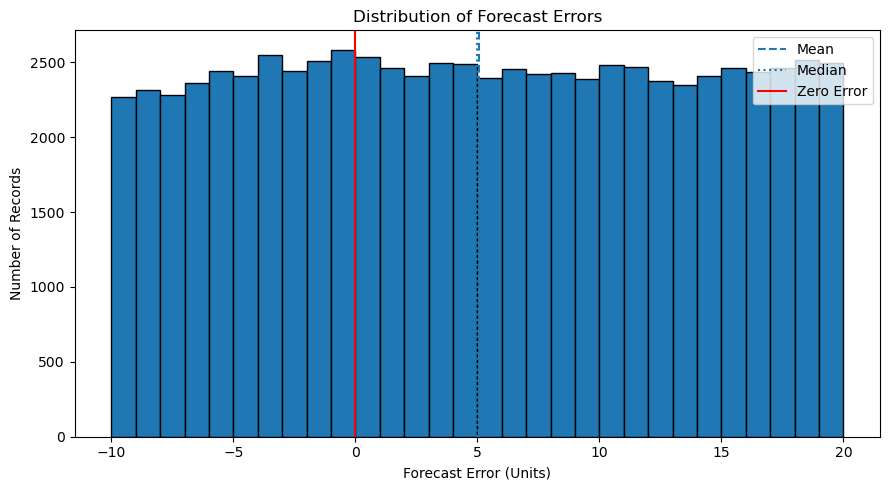

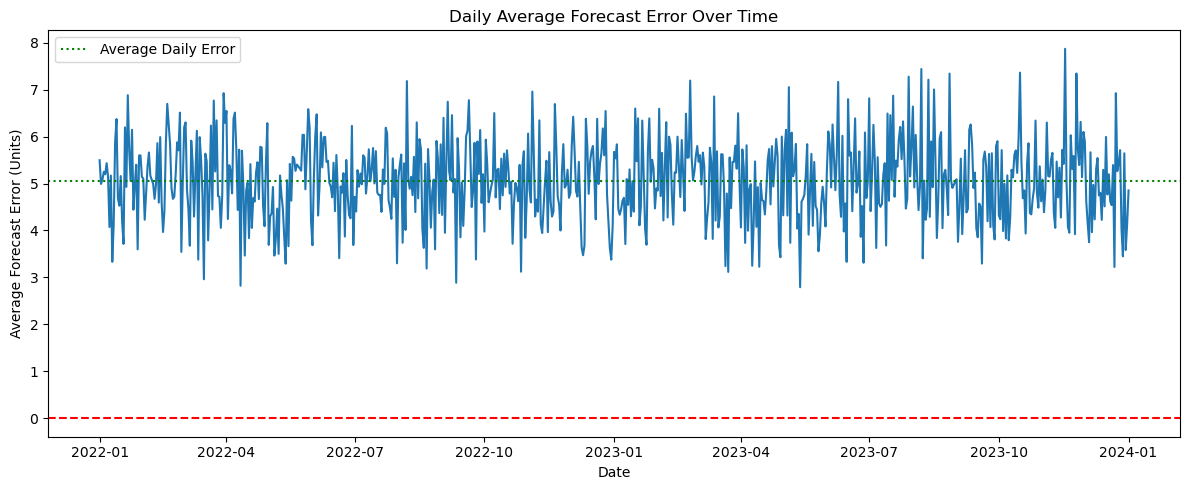

In [4]:

import matplotlib.pyplot as plt

# Plot 1: Individual record-level forecast errors
plt.figure(figsize=(9, 5))

plt.hist(df["forecast_error"], bins=30, edgecolor="black")

plt.axvline(
    df["forecast_error"].mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df["forecast_error"].median(),
    linestyle=":",
    label="Median"
)

plt.axvline(0, color="red", label="Zero Error")

plt.title("Distribution of Forecast Errors")
plt.xlabel("Forecast Error (Units)")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()


# Plot 2: Daily average forecast error
plt.figure(figsize=(12, 5))

plt.plot(
    daily_error.index,
    daily_error.values
)

plt.axhline(0, color="red", linestyle="--")

plt.axhline(
    daily_error.mean(),
    color="green",
    linestyle=":",
    label="Average Daily Error"
)

plt.title("Daily Average Forecast Error Over Time")
plt.xlabel("Date")
plt.ylabel("Average Forecast Error (Units)")
plt.legend()
plt.tight_layout()
plt.show()


Initial Findings

The descriptive analysis provides evidence of a consistent overforecasting pattern:

Mean and median forecast errors are positive.

Approximately 66.74% of records are overforecasted.

All 100 store-product combinations have positive average forecast errors.

All 731 dates have positive average forecast errors.

These findings are descriptive and do not yet establish statistical significance.

Autocorrelation Check

Before hypothesis testing, we will check whether daily forecast errors are related to errors from previous days.


<Figure size 1000x500 with 0 Axes>

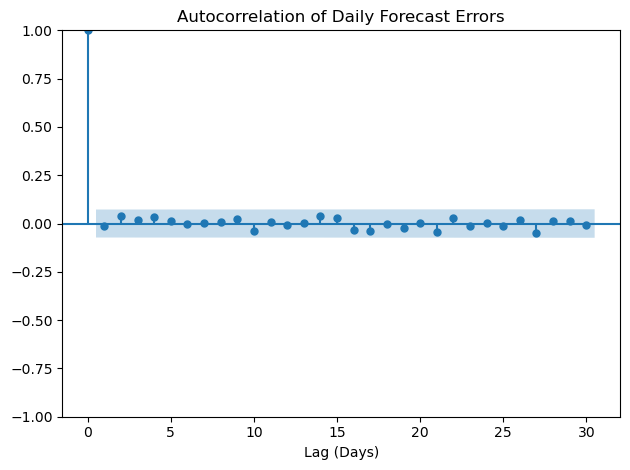

In [5]:

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Keep daily errors in date order
daily_error = daily_error.sort_index()

# Plot autocorrelation for the first 30 lags
plt.figure(figsize=(10, 5))

plot_acf(daily_error, lags=30)

plt.title("Autocorrelation of Daily Forecast Errors")
plt.xlabel("Lag (Days)")
plt.tight_layout()
plt.show()


**Observation:** The ACF graph shows that autocorrelation values for the first 30 lags are mostly within the confidence limits. No strong time-dependent pattern is visible in daily forecast errors.

In [6]:

print("Autocorrelation Values")

for lag in [1, 7, 14, 30]:
    print(
        f"Lag {lag}: "
        f"{daily_error.autocorr(lag=lag):.4f}"
    )


Autocorrelation Values
Lag 1: -0.0123
Lag 7: 0.0052
Lag 14: 0.0395
Lag 30: -0.0090


**Observation:** Autocorrelation values at lags 1, 7, 14 and 30 are very close to zero. This indicates very weak linear relationships between daily forecast errors at these intervals.

In [7]:

from statsmodels.stats.diagnostic import acorr_ljungbox

result = acorr_ljungbox(
    daily_error,
    lags=[7, 14, 30],
    return_df=True
)

print(result)


      lb_stat  lb_pvalue
7    2.509231   0.926400
14   5.416263   0.979135
30  12.635107   0.997725


**Observation:** All Ljung-Box p-values are greater than 0.05. Therefore, we fail to reject the null hypothesis and find no statistically significant evidence of autocorrelation up to 30 lags.

Our finding
- Daily forecast errors show very weak autocorrelation.
- No statistically significant autocorrelation was detected up to 30 lags.
- Daily observations appear reasonably suitable for our planned simple hypothesis test, based on this check.

Hypothesis Testing — Is average forecast error significantly greater than zero?

In [8]:

from scipy.stats import ttest_1samp

# Test whether average daily forecast error
# is significantly greater than zero

t_stat, p_two_tailed = ttest_1samp(
    daily_error,
    popmean=0
)

# Convert two-tailed p-value into one-tailed p-value
if t_stat > 0:
    p_one_tailed = p_two_tailed / 2
else:
    p_one_tailed = 1 - (p_two_tailed / 2)

print("One-Sample T-Test Results")
print("-------------------------")
print("Sample Mean:", daily_error.mean())
print("T-Statistic:", t_stat)
print("One-Tailed P-Value:", p_one_tailed)

if p_one_tailed < 0.05:
    print("\nConclusion: Reject the Null Hypothesis.")
    print("Average forecast error is significantly greater than zero.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis.")
    print("Insufficient evidence that average forecast error is greater than zero.")


One-Sample T-Test Results
-------------------------
Sample Mean: 5.063856634746922
T-Statistic: 158.48967818293573
One-Tailed P-Value: 0.0

Conclusion: Reject the Null Hypothesis.
Average forecast error is significantly greater than zero.


### One-Sample T-Test

**Purpose:** To check whether the average daily forecast error is significantly greater than zero.

**Results:**
- Sample Mean: +5.06 units
- T-Statistic: 158.49
- One-Tailed P-Value: Approximately 0
- Significance Level: 0.05

**Conclusion:** The p-value is below 0.05, so we reject the null hypothesis. There is strong statistical evidence that the average daily forecast error is greater than zero, indicating consistent forecast overestimation.

**Business Interpretation:** The overforecasting pattern identified in Power BI is also supported by statistical hypothesis testing.

In [9]:

from scipy import stats
import numpy as np

# Calculate sample mean and standard error
mean_error = daily_error.mean()
standard_error = stats.sem(daily_error)

# Calculate 95% confidence interval
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(daily_error) - 1,
    loc=mean_error,
    scale=standard_error
)

print("95% Confidence Interval")
print("-----------------------")
print("Lower Bound:", confidence_interval[0])
print("Upper Bound:", confidence_interval[1])
print("Average Daily Error:", mean_error)


95% Confidence Interval
-----------------------
Lower Bound: 5.001130408395485
Upper Bound: 5.126582861098359
Average Daily Error: 5.063856634746922


### 95% Confidence Interval

**Purpose:** To estimate the range of the population's average daily forecast error.

**Results:**
- Average Daily Error: +5.0639 units
- Lower Bound: +5.0011 units
- Upper Bound: +5.1266 units
- Confidence Level: 95%

**Conclusion:** The 95% confidence interval ranges from approximately +5.001 to +5.127 units. Since the entire interval is above zero, it supports the finding that average daily forecast error is positive.

**Business Interpretation:** The estimated average daily forecast overestimation is approximately 5.06 units.

Business Question: Is our demand forecast consistently overestimating actual demand?

Yes. Our descriptive analysis and statistical hypothesis test both support a consistent positive forecast bias in the observed dataset.

The average daily forecast error is approximately 5.06 units, and the 95% confidence interval remains entirely above zero.

For Easier understing what we did -

Investigation 1 — Is our demand forecast consistently overestimating actual demand?
Humein kya pata karna tha?

Company jo demand forecast kar rahi hai, kya woh actual sales se baar-baar zyada estimate kar rahi hai?
Step-by-step: Humne kya kiya aur kya pata chala?
1. Forecast Error Calculate Kiya
- Humein forecast aur actual sales ka difference pata karna tha.
- Isliye forecast mein se actual sales minus ki.
- Result: Average error +5.06 units mila.
Matlab average observation mein company actual sales se approximately 5 units zyada forecast kar rahi thi.

2. Overforecasting Kitni Baar Hui, Check Kiya
- Humein pata karna tha ki ye problem kitne records mein aa rahi hai.
- Isliye records ko Over, Under aur Exact Forecast mein divide kiya.
- Result: 66.74% records Overforecasted the.
Matlab lagbhag har 3 mein se 2 records mein forecast actual sales se zyada tha.

3. Store aur Product Combination Check Kiya
- Humein dekhna tha ki kya problem sirf kuch stores ya products mein hai.
- Isliye har store-product combination ka average error nikala.
- Result: Saare 100 combinations ka average error positive tha.
Matlab problem sirf kuch selected products ya stores tak limited nahi thi.

4. Daily Error Check Kiya
- Humein pata karna tha ki kya overforecasting poore time period mein ho rahi thi.
- Isliye har date ka average forecast error nikala.
- Result: 731 mein se sabhi 731 dates par average error positive tha.
Matlab daily level par bhi overforecasting poore observed period mein dikhi.

5. Error Distribution Graph Banaya
- Humein samajhna tha ki errors ka overall pattern kaisa hai.
- Isliye histogram banaya.
- Result: Errors negative aur positive dono the, lekin unka average positive side par tha.
Matlab individual records mein underforecasting bhi hui, lekin overall pattern overforecasting ka tha.

6. Daily Trend Graph Banaya
- Humein dekhna tha ki time ke saath overforecasting badh rahi hai ya kam ho rahi hai.
- Isliye daily average error ka line chart banaya.
- Result: Daily errors fluctuate hue, lekin koi clear long-term upward ya downward trend nahi dikha.
Matlab overforecasting continue rahi, lekin usmein koi obvious long-term direction nahi dikhi.

7. Autocorrelation Check Kiya
- Humein pata karna tha ki ek din ki error ka agle din ki error se koi strong connection hai ya nahi.
- Isliye graph, numerical correlation aur Ljung-Box test use kiya.
- Result: 30 days tak significant autocorrelation ka evidence nahi mila.
Matlab daily errors mein strong time-dependence detect nahi hui. Isse hypothesis testing ke liye simple approach consider karna reasonable tha.

8. Hypothesis Testing Kiya
- Ab humein verify karna tha ki average overforecasting sirf hamare dataset mein dikh rahi hai ya statistically meaningful evidence bhi hai.
- Isliye One-Sample T-Test lagaya.
- Result: P-value 0.05 se bahut kam aayi, aur humne Null Hypothesis reject kar di.
Matlab average forecast error statistically zero se greater hone ka strong evidence mila.

9. 95% Confidence Interval Nikala
- Humein average overforecasting ka estimated range pata karna tha.
- Isliye 95% Confidence Interval calculate kiya.
- Result: +5.001 se +5.127 units.
Matlab estimated average daily forecast error approximately 5.06 units hai, aur uska confidence interval poora positive hai.